<hr style="height:.9px;border:none;color:#333;background-color:#333;" />
<hr style="height:.9px;border:none;color:#333;background-color:#333;" />

<h1>Riding the Demand Curve</h1>
<h3>Hourly Bike Rental Forecasting and Demand Drivers for Cook County</h3>

<strong>Prepared for:</strong> Cook County Planning and Development Department<br>
<strong>Prepared by:</strong> Seyha Seng<br>
<strong>Course:</strong> DAT-7470 Business Analysis with Structured Data - Final Assignment<br>
Hult International Business School<br>
<hr style="height:.9px;border:none;color:#333;background-color:#333;" />
<hr style="height:.9px;border:none;color:#333;background-color:#333;" />

<h2>Analysis Introduction</h2>

Cook County asked us to predict how many bikes are rented in an hour and to explain what drives this demand. The county already has a large bike-share system, Divvy, and research on its trips shows that members ride mostly during weekday commute periods (Lu et al., 2026). Getting demand right matters, because too few bikes at busy times means lost trips, and maintenance at busy times removes bikes when riders need them. The data contains 678 hours from March to June, with the hour, day, month, holiday flag, weather and number of rentals for each hour. Demand changes a lot from hour to hour, from 9 to 3,734 rentals, with an average of 952 rentals per hour. The file has hours but no full dates, so we predict rentals for one hour rather than for a whole day. We answer three questions (why people rent bikes, which weather factor matters most, and when demand is low enough for maintenance), and then choose the model with the highest test R-square among the models with a train-test gap of 0.05 or less. Our main findings are that demand follows the work commute, temperature is the leading weather factor, and cool nights from 2 to 6 am are the quietest time. The final linear model explains about 83% of the variation in rentals on hours it had not seen before. The data covers only spring and early summer, so the results should be checked again with data from the rest of the year.

<hr style="height:.9px;border:none;color:#333;background-color:#333;" />
<h2>Part I: Setup</h2>
<h4>Imports</h4>

In [1]:
# importing libraries
import os                                              # locating the dataset
import numpy as np                                     # mathematical essentials
import pandas as pd                                    # data science essentials
import matplotlib.pyplot as plt                        # data visualization
import seaborn as sns                                  # enhanced data visualization
from sklearn.model_selection import train_test_split   # train-test split
from sklearn.model_selection import cross_val_score    # cross-validation inside the training set
from sklearn.model_selection import KFold              # folds for cross-validation
from sklearn.linear_model import LinearRegression      # linear regression
from sklearn.tree import DecisionTreeRegressor         # regression trees
from sklearn.tree import plot_tree                     # tree plots
from sklearn.preprocessing import StandardScaler       # standardizing x-features
from time import perf_counter                           # execution timing
from sklearn.pipeline import make_pipeline              # fold-safe weather scaling
from sklearn.metrics import r2_score                     # original-scale evaluation
from IPython.display import display                     # compact tables
started = perf_counter()


# Display precision does not change the full-precision selection calculations.
pd.set_option("display.precision", 4)

<h4>Loading the Dataset</h4>Keep <code>bike_rentals.xlsx</code> in the same folder as this notebook, then choose Run All.

In [2]:
# looking for the dataset next to the notebook (or in a datasets folder / Colab)
file = next((path for path in ['./bike_rentals.xlsx', './datasets/bike_rentals.xlsx',
                              '/content/bike_rentals.xlsx'] if os.path.exists(path)), None)

# stopping with a clear message if the file is missing
if file is None:
    raise FileNotFoundError('Place bike_rentals.xlsx beside this notebook, then Run All.')

# reading the data
bikes = pd.read_excel(file, sheet_name='Data')


# checking that the columns are the ones we expect
expected = ['ID', 'Month', 'Day of Week', 'Hour', 'Temperature', 'Humidity',
            'Wind Speed', 'Visibility', 'Dew Point Temperature', 'UV Index',
            'Rainfall', 'Snowfall', 'Seasons', 'Holiday', 'RENTALS']
assert bikes.columns.tolist() == expected, 'Unexpected dataset columns.'

# checking for missing values and a constant Snowfall column
assert bikes.notna().all().all(), 'Missing data requires an explicit review.'
assert bikes['Snowfall'].nunique() == 1, 'Reconsider snowfall if it varies in new data.'

# keeping an untouched copy of the original data
raw_bikes = bikes.copy(deep=True)


# one train-test split (course settings) and 5 training folds, reused by every model
train_index, test_index = train_test_split(bikes.index, test_size=.35, random_state=702)
training_folds = KFold(n_splits=5, shuffle=True, random_state=702)

# first five rows
display(bikes.head(n=5))

,ID,Month,Day of Week,Hour,Temperature,Humidity,Wind Speed,Visibility,Dew Point Temperature,UV Index,Rainfall,Snowfall,Seasons,Holiday,RENTALS
0,1,Mar,Wednesday,1,2.1,97,0.2,859,1.6,0.00,0.0,0,Spring,Yes,158
1,2,Mar,Wednesday,2,2.0,97,1.0,580,1.5,0.00,0.0,0,Spring,Yes,191
2,3,Mar,Wednesday,4,1.6,97,1.1,636,1.1,0.00,0.0,0,Spring,Yes,31
3,4,Mar,Wednesday,5,2.2,97,2.9,362,1.7,0.00,0.0,0,Spring,Yes,12
4,5,Mar,Wednesday,12,0.5,46,4.7,1172,-9.8,2.49,0.0,0,Spring,Yes,333


<h4>User-Defined Functions</h4>These functions put every model on the same train-test split and turn tree paths into readable rules.

In [3]:
def run_model(model, x_data, y_data, name):
    """Fit one candidate on the fixed partition; retain unrounded scores."""
    # safety checks: rows line up, and no target or ID on the x-side
    assert x_data.index.equals(y_data.index), 'Inputs and target must align.'
    assert not {'RENTALS', 'ID'}.intersection(x_data.columns), 'Target or ID leakage.'

    # same training and testing rows for every model
    x_train, x_test = x_data.loc[train_index], x_data.loc[test_index]
    y_train, y_test = y_data.loc[train_index], y_data.loc[test_index]

    # Validate within training rows; the returned test score is exploratory evaluation.
    fold_scores = cross_val_score(model, x_train, y_train, cv=training_folds, n_jobs=1)

    # fitting on training rows, then scoring R-square on both sets
    model.fit(x_train, y_train)
    train_score = model.score(x_train, y_train)
    test_score = model.score(x_test, y_test)

    # Gap eligibility uses exact floats; only presentation is rounded later.
    summary = {'Model': name, 'X-Features': x_data.shape[1],
               'CV R2 (train only)': fold_scores.mean(), 'CV SD': fold_scores.std(),
               'Training R2': train_score, 'Testing R2': test_score,
               'Abs. Gap': abs(train_score - test_score)}
    return summary, model


def standardized_weather_model(x_data, y_data, weather_cols, name):
    """Explain coefficients on training data and assess drop-one importance by CV."""
    # same training and testing rows as every other model
    x_train, x_test = x_data.loc[train_index].copy(), x_data.loc[test_index].copy()
    y_train, y_test = y_data.loc[train_index], y_data.loc[test_index]

    # Fit only training weather scales; calendar indicators retain their original units.
    scaler = StandardScaler().fit(x_train[weather_cols])
    x_train[weather_cols] = scaler.transform(x_train[weather_cols])
    x_test[weather_cols] = scaler.transform(x_test[weather_cols])

    # standardized coefficients of the weather columns only
    model = LinearRegression().fit(x_train, y_train)
    coefs = pd.Series(model.coef_, index=x_data.columns)[weather_cols]

    # Each fold learns its own scaling; no held-out outcome ranks weather factors.
    fold_model = make_pipeline(StandardScaler(), LinearRegression())
    cv_score = cross_val_score(fold_model, x_data.loc[train_index], y_train,
                               cv=training_folds, n_jobs=1).mean()

    # drop-one check: how much CV R-square is lost when each weather factor is removed
    loss = {}
    for factor in weather_cols:
        reduced = x_data.loc[train_index].drop(columns=factor)
        omitted_score = cross_val_score(fold_model, reduced, y_train,
                                        cv=training_folds, n_jobs=1).mean()
        loss[factor] = cv_score - omitted_score

    # one summary row for the comparison table
    summary = {'Model': name, 'Training R2': model.score(x_train, y_train),
               'Testing R2': model.score(x_test, y_test), 'CV R2': cv_score}
    return summary, coefs, pd.Series(loss)


def leaf_conditions(tree, feature_names):
    """Preserve unrounded numeric thresholds for all complete tree paths."""
    structure, paths = tree.tree_, {}

    # walking from the root and storing the conditions on the way to each leaf
    def walk(node, path):
        # a node without children is a leaf: save its full path
        if structure.children_left[node] == -1:
            paths[node] = path
            return
        feature = feature_names[structure.feature[node]]
        threshold = float(structure.threshold[node])
        # Path membership must use these internal values, not rounded text labels.
        walk(structure.children_left[node], path + [(feature, '<=', threshold)])
        walk(structure.children_right[node], path + [(feature, '>', threshold)])
    walk(0, [])
    return paths


def leaf_rules(tree, feature_names):
    """Format complete paths while retaining enough precision to identify splits."""
    return {leaf: [f'{f} {op} {threshold:.8g}' for f, op, threshold in path]
            for leaf, path in leaf_conditions(tree, feature_names).items()}

<hr style="height:.9px;border:none;color:#333;background-color:#333;" />
<h2>Part II: Data Audit</h2>

In [4]:
# key quality checks in one compact summary
audit = pd.Series({
    # size and completeness
    'Rows (hours)'                 : bikes.shape[0],
    'Columns'                      : bikes.shape[1],
    'Missing values'               : bikes.isnull().sum().sum(),
    'Duplicate rows (ignoring ID)' : bikes.drop(columns = 'ID').duplicated().sum(),
    'Text columns'                 : ', '.join(bikes.select_dtypes(exclude = 'number').columns),

    # coverage of the calendar
    'Months covered'               : ', '.join(bikes['Month'].unique()),
    'Seasons covered'              : ', '.join(bikes['Seasons'].unique()),

    # columns that carry no usable information
    'Distinct Snowfall values'     : bikes['Snowfall'].nunique(),
    'Sequential ID'             : bikes['ID'].is_monotonic_increasing,

    # suspicious or capped measurements
    'Hours with Humidity = 0'      : (bikes['Humidity'] == 0).sum(),
    'Hours with any rain'          : (bikes['Rainfall'] > 0).sum(),
    'Maximum UV Index'             : bikes['UV Index'].max(),
    'Two largest Rainfall values'  : ', '.join(bikes['Rainfall'].nlargest(2).astype(str)),
    'Hours at Visibility cap 2,000': (bikes['Visibility'] == 2000).sum()
})

audit

Rows (hours)                                                      678
Columns                                                            15
Missing values                                                      0
Duplicate rows (ignoring ID)                                        0
Text columns                     Month, Day of Week, Seasons, Holiday
Months covered                                    Mar, Apr, May, June
Seasons covered                                        Spring, Summer
Distinct Snowfall values                                            1
Sequential ID                                                    True
Hours with Humidity = 0                                             1
Hours with any rain                                                60
Maximum UV Index                                                 3.39
Two largest Rainfall values                                 35.0, 5.4
Hours at Visibility cap 2,000                                     116
dtype: object

In [5]:
# distribution of the response variable (rentals per hour)
bikes['RENTALS'].describe().round(0)

count     678.0
mean      952.0
std       772.0
min         9.0
25%       310.0
50%       780.0
75%      1351.0
max      3734.0
Name: RENTALS, dtype: float64

**What the data audit shows**

* The data is complete, with 678 hours, no missing values and no duplicate rows.
* Rentals range from 9 to 3,734 per hour, and the mean (952) is above the median (780) because a few hours are very busy.
* Snowfall is always 0, so it cannot explain any change in rentals and is left out.
* ID is only a row number, so it is left out of every model.
* The file does not give units, but the temperatures (-6.6 to 32.7) look like degrees Celsius.
* A few values should be checked with the client: one hour has 0% humidity, the "UV Index" never goes above 3.39, and 116 hours have a visibility of exactly 2,000.
* A Wednesday in March is marked as a holiday, but there is no U.S. federal holiday in March, so the holiday coding should be confirmed.
* One hour has a Rainfall value of 35, far above every other hour (the next highest is 5.4), and this matters for the final model.

<hr style="height:.9px;border:none;color:#333;background-color:#333;" />
<h2>Part III: Feature Engineering</h2>
All new features are yes/no flags or categories made from existing columns. None of them uses RENTALS, powers or roots.

In [6]:
# calendar flags
bikes['weekend'] = bikes['Day of Week'].isin(['Saturday', 'Sunday']).astype(int)
bikes['holiday'] = (bikes['Holiday'] == 'Yes').astype(int)
bikes['offday']  = ((bikes['weekend'] + bikes['holiday']) > 0).astype(int)  # calendar proxy, not a trip-purpose label


# commute flags: working days during the morning and evening rush
bikes['rush']    = ((bikes['offday'] == 0) & bikes['Hour'].isin([7, 8, 9, 17, 18, 19])).astype(int)
bikes['am_peak'] = ((bikes['offday'] == 0) & (bikes['Hour'] == 8)).astype(int)
bikes['pm_peak'] = ((bikes['offday'] == 0) & bikes['Hour'].isin([17, 18, 19])).astype(int)


# weather flags
bikes['rain']       = (bikes['Rainfall'] > 0).astype(int)    # any precipitation in the hour
bikes['humid_high'] = (bikes['Humidity'] >= 80).astype(int)  # muggy or wet air


# warm-evening indicator: temperature 15 or higher in supplied units between 4 pm and 10:59 pm (after-work and leisure riding)
bikes['pleasant_evening'] = ((bikes['Temperature'] >= 15) & bikes['Hour'].between(16, 22)).astype(int)


# Month ordering helps tree thresholds; no elapsed date is inferred.
bikes['month_num'] = bikes['Month'].map({'Mar': 3, 'Apr': 4, 'May': 5, 'June': 6})


# readable day type for charts
bikes['day_type'] = np.where(bikes['offday'] == 1, 'Weekend / Holiday', 'Working day')


# checking the new columns
bikes[ ['Hour', 'Day of Week', 'Holiday', 'offday', 'rush', 'rain', 'pleasant_evening'] ].head(n = 5)

,Hour,Day of Week,Holiday,offday,rush,rain,pleasant_evening
0,1,Wednesday,Yes,1,0,0,0
1,2,Wednesday,Yes,1,0,0,0
2,4,Wednesday,Yes,1,0,0,0
3,5,Wednesday,Yes,1,0,0,0
4,12,Wednesday,Yes,1,0,0,0


In [7]:
# one hot encoding hour and month for the linear models (k-1 rule: first category dropped)
hour_dummies  = pd.get_dummies(bikes['Hour'],  prefix = 'hour',  dtype = int, drop_first = True)
month_dummies = pd.get_dummies(bikes['Month'], prefix = 'month', dtype = int, drop_first = True)


# weather features available to the client from any forecast
# (Snowfall is constant; Dew Point is almost fully explained by Temperature and Humidity, see Task 2)
weather = ['Temperature', 'Humidity', 'Wind Speed', 'Visibility', 'UV Index', 'Rainfall']


# response variable (never used on the x-side)
y_rentals = bikes['RENTALS']

<hr style="height:.9px;border:none;color:#333;background-color:#333;" />
<h2>Part IV: Task 1 - Leisure, Exercise or Commuting?</h2>
We compare working days with weekends and holidays at the same hours of the day.

In [8]:
# average rentals for each hour, separately for working days and weekends/holidays
profile = bikes.pivot_table(index   = 'Hour',
                            columns = 'day_type',
                            values  = 'RENTALS',
                            aggfunc = 'mean')


# number of observed hours behind each line (shown in the legend)
hours_observed = bikes['day_type'].value_counts()


# comparing the same clock windows on working days and off-days (average per hour and sample size)
windows = {'Morning, 7-9 am' : [7, 8, 9],
           'Midday, 11 am-3 pm' : [11, 12, 13, 14, 15],
           'Evening, 5-7 pm' : [17, 18, 19]}

# average rentals and number of observed hours for each window and day type
window_table = pd.DataFrame({
    window : bikes[ bikes['Hour'].isin(hours) ].groupby('day_type')['RENTALS'].agg(['mean', 'count']).stack()
    for window, hours in windows.items()}).T


# readable column names and the working-day / off-day ratio
window_table.columns = [f"{day} - {stat}" for day, stat in window_table.columns]
window_table['Working / Off-day ratio'] = (window_table['Working day - mean'] /
                                           window_table['Weekend / Holiday - mean'])
window_table.round(0).assign(**{'Working / Off-day ratio' : window_table['Working / Off-day ratio'].round(2)})

,Weekend / Holiday - mean,Weekend / Holiday - count,Working day - mean,Working day - count,Working / Off-day ratio
"Morning, 7-9 am",611.0,23.0,1087.0,62.0,1.78
"Midday, 11 am-3 pm",1042.0,51.0,991.0,103.0,0.95
"Evening, 5-7 pm",1661.0,25.0,1861.0,67.0,1.12


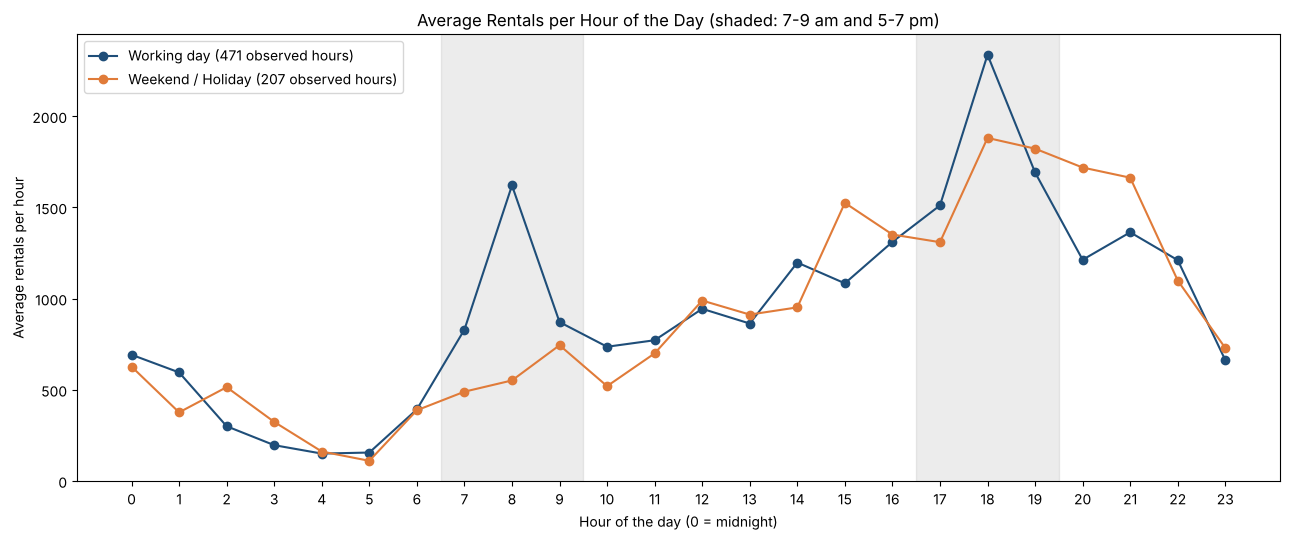

In [9]:
# hourly demand profile: working days vs weekends/holidays
fig, ax = plt.subplots(figsize = (13, 5.5))


# one line per day type, with the number of observed hours in the legend
for day, color in [('Working day', '#1f4e79'), ('Weekend / Holiday', '#e07b39')]:
    ax.plot(profile.index, profile[day], marker = 'o', color = color,
            label = f"{day} ({hours_observed[day]} observed hours)")


# shading the conventional commute windows
ax.axvspan(6.5, 9.5,   color = 'grey', alpha = 0.15)
ax.axvspan(16.5, 19.5, color = 'grey', alpha = 0.15)


# titles, labels and legend
ax.set_title('Average Rentals per Hour of the Day (shaded: 7-9 am and 5-7 pm)')
ax.set_xlabel('Hour of the day (0 = midnight)')
ax.set_ylabel('Average rentals per hour')
ax.set_xticks(range(0, 24, 1))
ax.legend()


# rendering the figure
plt.tight_layout()
plt.show()

**What the hourly pattern shows**

* The blue line shows working days (471 hours), and the orange line shows weekends and holidays (207 hours).
* Working days have a sharp peak at 8 am with about 1,620 rentals, and the highest peak of the day at 6 pm with about 2,340 rentals.
* Weekends and holidays have no morning peak, and their demand grows slowly from late morning into the evening.
* At midday the two lines are almost the same, and off-days are slightly busier (1,040 against 990 rentals per hour).
* This means the difference between the two lines comes from the commute hours, mostly in the morning.
* Each point is an average of about 20 working-day hours or 9 off-day hours, so single points are noisy.

In [10]:
# supporting evidence 1: how much busier the commute peaks are on working days
peaks = profile.loc[[8, 18]].round(0)
peaks['Working day / Off-day'] = (peaks['Working day'] / peaks['Weekend / Holiday']).round(2)
peaks

day_type,Weekend / Holiday,Working day,Working day / Off-day
Hour,,,
8,551.0,1620.0,2.94
18,1881.0,2337.0,1.24


In [11]:
# supporting evidence 2: holidays vs normal working days at the SAME hours of the day
holiday_hours = bikes[ bikes['holiday'] == 1 ]
workday_means = bikes[ bikes['offday'] == 0 ].groupby('Hour')['RENTALS'].mean()

holiday_ratio = holiday_hours['RENTALS'].sum() / workday_means[holiday_hours['Hour']].sum()
print(f"Holiday demand vs a normal working day (same hours): {holiday_ratio:.0%}")

Holiday demand vs a normal working day (same hours): 87%


In [12]:
# supporting evidence 3: does the morning commute pattern hold within EACH month?
morning = bikes[ bikes['Hour'].isin([7, 8, 9]) ].pivot_table(index   = 'Month',
                                                            columns = 'day_type',
                                                            values  = 'RENTALS',
                                                            aggfunc = 'mean')

# ratio above 1 means working-day mornings are busier than off-day mornings
morning['Working / Off-day'] = morning['Working day'] / morning['Weekend / Holiday']
morning.loc[ ['Mar', 'Apr', 'May', 'June'] ].round({'Weekend / Holiday' : 0,
                                                    'Working day'       : 0,
                                                    'Working / Off-day' : 2})

day_type,Weekend / Holiday,Working day,Working / Off-day
Month,,,
Mar,355.0,681.0,1.92
Apr,628.0,940.0,1.49
May,537.0,1350.0,2.51
June,879.0,1529.0,1.74


<h3>Answer: Commuting</h3>

The data fits commuting best, because at 8 am working days have 2.9 times more rentals than weekends and holidays. Between 7 and 9 am working days are 1.8 times busier, between 5 and 7 pm they are 1.1 times busier, and at midday both are about the same (0.95). The weekday morning increase is consistent with commuting, although leisure trips may also happen on weekdays. The pattern holds in every month, as working-day mornings are 1.5 to 2.5 times busier in March, April, May and June. On holidays, demand falls to 87% of a normal working day at the same hours, but there are only 21 holiday hours, so this is a hint rather than proof. Exercise cannot be separated reliably from leisure or commuting, because the dataset has no trip-purpose labels. Research agrees with this result: Chicago Divvy member trips are linked to weekday commute times (Lu et al., 2026), and in 40 bike-share cities weekday use has morning and evening peaks while weekend use peaks in the afternoon (Bean et al., 2021). The data has no trip-purpose field, so we cannot prove that more than half of all trips are commutes, but commuting is clearly the main pattern. Cook County should therefore plan bike availability around the working-day morning and evening peaks first.

<hr style="height:.9px;border:none;color:#333;background-color:#333;" />
<h2>Part V: Task 2 - The Most Important Weather Factor (Linear Model)</h2>

* The weather columns use different scales, so we standardize them (mean 0, standard deviation 1) on the training rows before comparing coefficients.
* A standardized coefficient shows how many rentals per hour change when a factor moves by one typical amount (one standard deviation).
* We compare three linear models: one with all weather columns, one without Dew Point, and one with weather plus hour, month and day type.

In [13]:
# redundancy check: how much of Dew Point can be explained by Temperature and Humidity together?
dew_check = LinearRegression().fit(bikes.loc[train_index, ['Temperature', 'Humidity']], bikes.loc[train_index, 'Dew Point Temperature'])

print(f"Share of Dew Point variation explained by Temperature and Humidity: "
      f"{dew_check.score(bikes.loc[train_index, ['Temperature', 'Humidity']], bikes.loc[train_index, 'Dew Point Temperature']):.1%}")

Share of Dew Point variation explained by Temperature and Humidity: 96.6%


In [14]:
# all weather-related columns, including Dew Point (Snowfall is always 0 and is excluded)
weather_all = weather + ['Dew Point Temperature']


# calendar controls: hour of day, month and type of day
calendar_controls = pd.concat([hour_dummies, month_dummies, bikes[ ['offday'] ]], axis = 1)


# specification 1: all weather factors including Dew Point
sum_1, coef_1, loss_1 = standardized_weather_model(bikes[weather_all], y_rentals, weather_all,
                                                   'Weather only (with Dew Point)')

# specification 2: Dew Point removed (97% of its variation is explained by Temperature and Humidity)
sum_2, coef_2, loss_2 = standardized_weather_model(bikes[weather], y_rentals, weather,
                                                   'Weather only (no Dew Point)')

# specification 3: weather plus calendar controls, so weather is compared at the same hour, month and day type
sum_3, coef_3, loss_3 = standardized_weather_model(pd.concat([bikes[weather], calendar_controls], axis = 1),
                                                   y_rentals, weather,
                                                   'Weather + calendar controls')

pd.DataFrame([sum_1, sum_2, sum_3])

,Model,Training R2,Testing R2,CV R2
0,Weather only (with Dew Point),0.5173,0.5080,0.3971
1,Weather only (no Dew Point),0.5139,0.5031,0.3626
2,Weather + calendar controls,0.7159,0.7301,0.4785


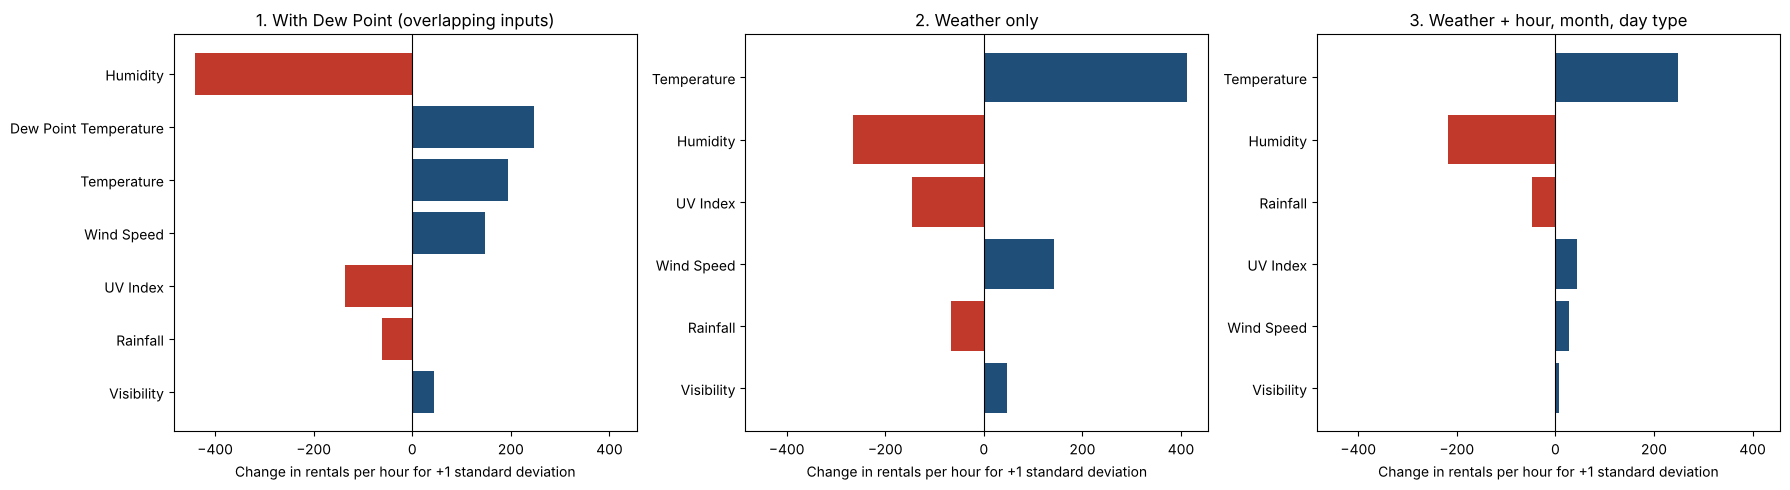

In [15]:
# standardized weather coefficients of the three specifications
fig, ax = plt.subplots(nrows = 1, ncols = 3, figsize = (18, 5), sharex = True)

for axis, coefs, title in [(ax[0], coef_1, '1. With Dew Point (overlapping inputs)'),
                           (ax[1], coef_2, '2. Weather only'),
                           (ax[2], coef_3, '3. Weather + hour, month, day type')]:
    coefs = coefs.reindex(coefs.abs().sort_values().index)            # largest effect on top
    axis.barh(coefs.index, coefs.values,
              color = ['#c0392b' if v < 0 else '#1f4e79' for v in coefs.values])
    axis.axvline(0, color = 'black', linewidth = 0.8)
    axis.set_title(title)
    axis.set_xlabel('Change in rentals per hour for +1 standard deviation')


# rendering the figure
plt.tight_layout()
plt.show()

**What the weather coefficients show**

* A longer bar means that a typical change in that factor has a bigger effect on rentals.
* In panel 1 humidity looks strongest, but Dew Point overlaps with temperature and humidity (they explain about 97% of it), so the model splits their effects.
* Without Dew Point (panel 2), temperature clearly leads with +413 rentals per typical rise, against -266 for humidity.
* When hour, month and day type are held constant (panel 3), temperature still leads with +248, ahead of humidity with -217.
* The gap between them is smaller in panel 3 because month already captures part of the warming from March to June.
* UV Index changes from negative to positive once the hour is known, so its negative sign in panel 2 mostly reflected quiet middays.

In [16]:
# Report training-validation losses, rather than using test outcomes to rank factors.
# one standard deviation of each factor (training rows), to read the coefficients
weather_sd_train = bikes.loc[train_index, weather].std(ddof=0)

# losses for both specifications, largest loss (with calendar) first
display(pd.DataFrame({'CV R2 loss: weather only': loss_2,
                      'CV R2 loss: with calendar': loss_3,
                      'One training SD': weather_sd_train})
          .sort_values('CV R2 loss: with calendar', ascending=False).round(3))

,CV R2 loss: weather only,CV R2 loss: with calendar,One training SD
Humidity,0.219,0.164,22.140
Temperature,0.203,0.068,7.594
Wind Speed,0.046,0.001,0.996
UV Index,0.033,-0.002,1.015
Visibility,0.012,-0.011,635.535
Rainfall,-0.120,-0.162,1.766


In [17]:
# rain: rare but severe - comparing rainy and dry hours
rain_effect = bikes.groupby('rain').agg(count            = ('RENTALS', 'size'),
                                        mean_rentals     = ('RENTALS', 'mean'),
                                        median_humidity  = ('Humidity', 'median')).round(0)
rain_effect.index = ['Dry hours', 'Rainy hours']
rain_effect

,count,mean_rentals,median_humidity
Dry hours,618,1033.0,56.0
Rainy hours,60,116.0,96.0


<h3>Answer: Temperature has the largest effect; humidity adds the most extra information</h3>

Temperature has the largest standardized coefficient in both models without Dew Point (+413 and +248 rentals per typical change). Temperature is also the first split of the maintenance tree in Task 3. The ranking depends on the measure: temperature has the largest standardized coefficient, while removing humidity causes the larger validation R-square loss (0.164 against 0.068), so neither measure gives a universal winner. One reason is that humidity also signals wet weather, since rainy hours have a median humidity of 96%. Rain is severe but rare, as rainy hours average 116 rentals against 1,033 in dry hours, but only 60 of the 678 hours had rain. The Rainfall amount even lowers the CV score because of one extreme reading of 35, so a yes/no rain flag works better in the final model. The real-world logic is that in a cool spring, warmer weather makes riding more pleasant for both commuters and leisure riders. Research supports this, as ridership in Montréal rose by 43-50% when temperature doubled but fell above about 28 °C in high humidity (Miranda-Moreno & Nosal, 2011). Across 40 cities rain mattered more than temperature (Bean et al., 2021), so in a wetter season rain could matter more than it does here. Cook County should therefore use the full demand forecast, which includes temperature, humidity and rain, rather than any single weather factor.

<hr style="height:.9px;border:none;color:#333;background-color:#333;" />
<h2>Part VI: Task 3 - When Is Demand Low Enough for Maintenance? (Regression Tree)</h2>

* We build one pruned tree that uses only inputs known in advance: the hour, the weather, the day type and the month.
* We then take its quietest leaves until they cover at least 10% of the data, which is 68 hours.

In [18]:
# x-features for the maintenance tree (forecastable inputs only)
tree_features = ['Hour', 'Temperature', 'Humidity', 'Wind Speed', 'Visibility',
                 'UV Index', 'Rainfall', 'offday', 'rush', 'month_num']


# comparing minimum leaf sizes with 5-fold CV on training rows (depth fixed at 4 for readability)
tuning = []
for leaf_size in [5, 8, 10, 15, 20, 25]:
    model = DecisionTreeRegressor(max_depth=4, min_samples_leaf=leaf_size, random_state=702)

    # CV score on training rows only
    scores = cross_val_score(model, bikes.loc[train_index, tree_features],
                              y_rentals.loc[train_index], cv=training_folds, n_jobs=1)
    tuning.append({'Minimum leaf size': leaf_size, 'Training CV R2': scores.mean(),
                    'CV SD': scores.std()})

# tuning results
display(pd.DataFrame(tuning).set_index('Minimum leaf size').round(4))

,Training CV R2,CV SD
Minimum leaf size,,
5,0.5891,0.0528
8,0.6002,0.0808
10,0.6090,0.0536
15,0.6134,0.0794
20,0.5779,0.1059
25,0.5607,0.0987


**How we chose the tree settings**

* We fixed the depth at 4 so that each path is short enough to read.
* The CV scores for leaf sizes from 5 to 15 are close (0.589 to 0.613), so no setting clearly wins.
* We use at least 8 hours per leaf, because it is close to the best CV score and its train-test gap (0.038) meets the 0.05 rule.
* Leaves of 20 or 25 hours score lower because they mix quiet and busy hours.
* We also looked at the test gap when choosing, so this choice is not fully independent of the test set.

In [19]:
# x-features for the maintenance tree (interpretable, forecastable inputs)
tree_features = ['Hour', 'Temperature', 'Humidity', 'Wind Speed', 'Visibility',
                 'UV Index', 'Rainfall', 'offday', 'rush', 'month_num']


# developing ONE pruned regression tree
summary_tree, maintenance_tree = run_model(DecisionTreeRegressor(max_depth        = 4,
                                                                 min_samples_leaf = 8,
                                                                 random_state     = 702),
                                           bikes[tree_features], y_rentals,
                                           'Regression tree (depth 4, leaf 8)')

pd.DataFrame([summary_tree])

,Model,X-Features,CV R2 (train only),CV SD,Training R2,Testing R2,Abs. Gap
0,"Regression tree (depth 4, leaf 8)",10,0.6002,0.0808,0.7465,0.7081,0.0384


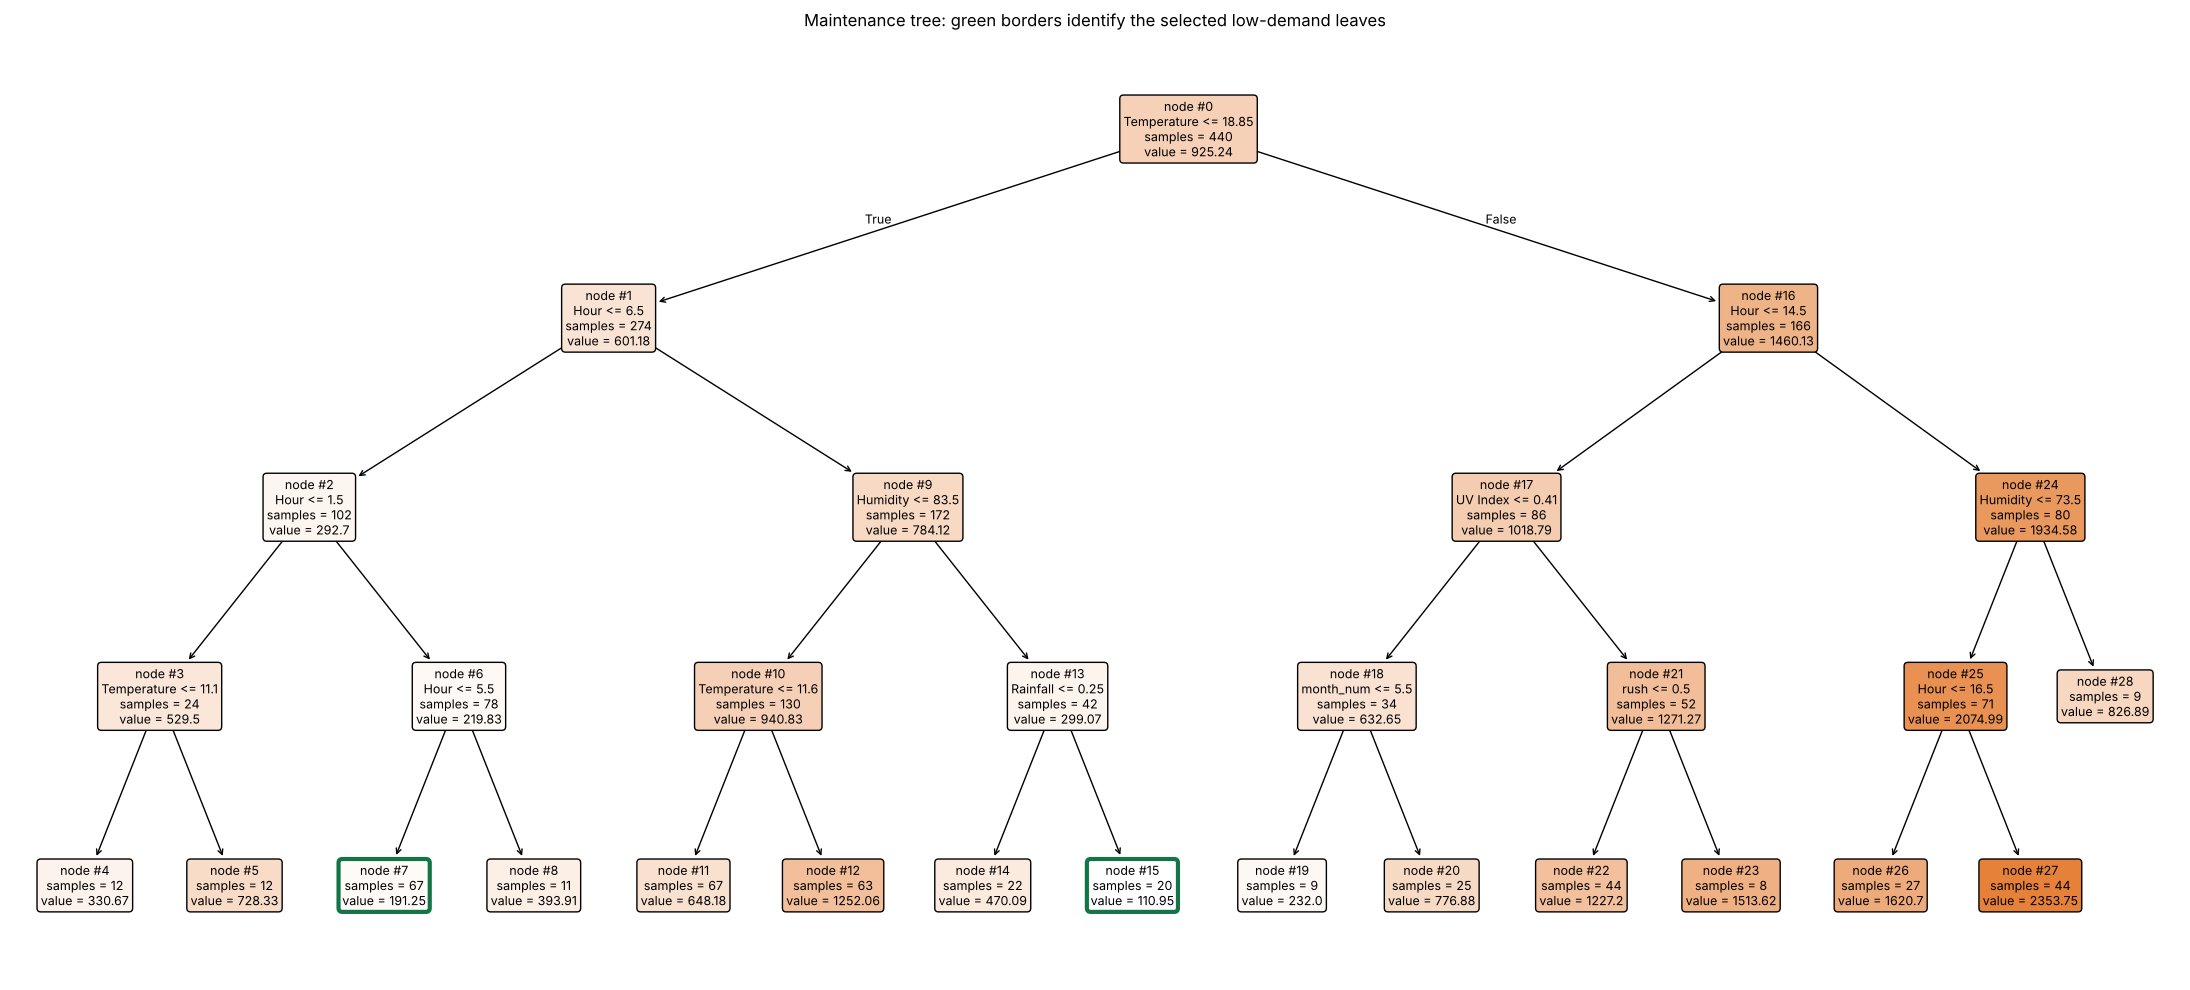

In [20]:
# Display node IDs and highlight the two lowest training-prediction leaves.
terminal = np.flatnonzero(maintenance_tree.tree_.children_left == -1)
low_nodes = sorted(terminal, key=lambda node: maintenance_tree.tree_.value[node].ravel()[0])[:2]
fig, ax = plt.subplots(figsize=(22, 10))
labels = plot_tree(maintenance_tree, feature_names=tree_features, filled=True,
                   rounded=True, fontsize=9, precision=2, node_ids=True,
                   impurity=False, ax=ax)
for label in labels:
    if label.get_text().split('\n')[0] in [f'node #{node}' for node in low_nodes]:
        label.get_bbox_patch().set_edgecolor('#137547')
        label.get_bbox_patch().set_linewidth(3)
ax.set_title('Maintenance tree: green borders identify the selected low-demand leaves')
fig.tight_layout()
plt.show()

**What the tree shows**

* The tree learns from 440 training hours and splits them into 15 groups (leaves), where darker boxes mean more rentals.
* The first split is temperature at 18.85, which shows that cooler hours have lower demand.
* For cool hours, the next split is the time of day, and hours before 7 am are quiet, especially from 2 to 6 am.
* The quietest leaf contains cool, very humid (above 83.5%) hours with rain (above 0.25), from 7 am onward.
* The busiest leaf contains warm, fairly dry hours from 5 pm onward, with about 2,350 rentals per hour.
* The green borders mark the two leaves that we select for maintenance.
* The tree is stable, with a training score of 0.746, a test score of 0.708 and a gap of 0.038.

In [21]:
# applying the SAME tree to all 678 hours to see which leaf each hour falls into
bikes['leaf'] = maintenance_tree.apply(bikes[tree_features])
rules = leaf_rules(maintenance_tree, tree_features)
paths = leaf_conditions(maintenance_tree, tree_features)


# one row per leaf: number of hours, average rentals and predicted (training) demand
leaves = bikes.groupby('leaf').agg(hours=('RENTALS', 'size'), avg_rentals=('RENTALS', 'mean'))
leaves['predicted'] = [maintenance_tree.tree_.value[node].ravel()[0] for node in leaves.index]
leaves['share'] = leaves.hours / len(bikes)

# lowest predicted demand first
leaves = leaves.sort_values('predicted')
leaves['cumulative'] = leaves.share.cumsum()


# adding the quietest leaves one by one until they cover at least 10% of the data (68 hours)
required_hours = int(np.ceil(.10 * len(bikes)))
selected_nodes, count = [], 0
for node, row in leaves.iterrows():
    selected_nodes.append(node)
    count += int(row.hours)
    if count >= required_hours:
        break

# the selected leaves and the hours they cover
selected = leaves.loc[selected_nodes]
union = bikes.leaf.isin(selected_nodes)
assert union.sum() >= required_hours


def plain_language(leaf):
    """Turns a leaf path into a clock-time window plus the other conditions."""
    lower, upper, other = 0, 23, []

    # hour splits become a start and end time; other splits stay as conditions
    for feature, op, threshold in paths[leaf]:
        if feature == 'Hour':
            if op == '>':
                lower = max(lower, int(np.floor(threshold)) + 1)
            else:
                upper = min(upper, int(np.floor(threshold)))
        else:
            sign = 'at most' if op == '<=' else 'above'
            other.append(f'{feature} {sign} {threshold:.2f}')
    return f'{lower:02d}:00–{upper:02d}:59; ' + '; '.join(other)


# summary table of the selected maintenance paths
maintenance_table = pd.DataFrame({
    'Tree node': selected.index,
    'Plain-language path': [plain_language(node) for node in selected.index],
    'Hours': selected.hours.to_numpy(), 'Dataset coverage %': selected.share.to_numpy() * 100,
    'Avg rentals / hour': selected.avg_rentals.to_numpy()})
display(maintenance_table.set_index('Tree node').round(1))
print(f'Combined unique coverage: {union.sum()} / {len(bikes)} ({union.mean():.1%})')

,Plain-language path,Hours,Dataset coverage %,Avg rentals / hour
Tree node,,,,
15,07:00–23:59; Temperature at most 18.85; Humidi...,29,4.3,103.9
7,02:00–05:59; Temperature at most 18.85,93,13.7,190.7


Combined unique coverage: 122 / 678 (18.0%)


In [22]:
# full decision path of the two lowest-demand nodes, with internal thresholds shown to eight significant figures
for rank, leaf in enumerate(selected_nodes, start = 1):
    print(f"Path {rank} (node {leaf}): " + "  AND  ".join(rules[leaf]))

Path 1 (node 15): Temperature <= 18.849999  AND  Hour > 6.5  AND  Humidity > 83.5  AND  Rainfall > 0.25
Path 2 (node 7): Temperature <= 18.849999  AND  Hour <= 6.5  AND  Hour > 1.5  AND  Hour <= 5.5


**The selected maintenance windows**

* Path A (node 7) covers cool nights from 2:00 to 5:59 am with a temperature of at most 18.85, which is 93 hours (13.7%) with about 191 rentals per hour.
* Path B (node 15) covers cool, very humid, rainy hours from 7 am onward, which is 29 hours (4.3%) with about 104 rentals per hour.
* Together the two paths cover 122 hours, or 18.0% of the data, which is above the 68 hours needed for 10%.
* These hours average 170 rentals against 1,123 in all other hours, and they hold only 3.2% of all rentals.
* Both paths come from the same fitted tree, as the assignment requires.

In [23]:
# demand during the two maintenance windows compared with all other hours
window = bikes['leaf'].isin(selected_nodes)          # True for hours in the selected nodes


# coverage, demand level and share of all rentals affected

print(f"Hours covered by the two paths : {window.sum()} of {len(bikes)} ({window.mean():.1%})")
print(f"Average rentals inside windows  : {bikes.loc[window,  'RENTALS'].mean():,.0f} per hour")
print(f"Average rentals outside windows : {bikes.loc[~window, 'RENTALS'].mean():,.0f} per hour")
print(f"Share of rental volume inside    : {bikes.loc[window, 'RENTALS'].sum() / bikes['RENTALS'].sum():.1%}  (disruption proxy)")


# held-out support: do the selected nodes stay quiet on the testing hours the tree never saw?
x_train, x_test, y_train, y_test = train_test_split(bikes[tree_features], y_rentals,
                                                    test_size = 0.35, random_state = 702)
for label, x_part, y_part in [('Training hours', x_train, y_train), ('Testing hours ', x_test, y_test)]:
    inside = np.isin(maintenance_tree.apply(x_part), selected_nodes)
    print(f"{label}: {inside.sum():3d} hours inside, average {y_part[inside].mean():,.0f} "
          f"vs {y_part[~inside].mean():,.0f} outside")

Hours covered by the two paths : 122 of 678 (18.0%)
Average rentals inside windows  : 170 per hour
Average rentals outside windows : 1,123 per hour
Share of rental volume inside    : 3.2%  (disruption proxy)
Training hours:  87 hours inside, average 173 vs 1,111 outside
Testing hours :  35 hours inside, average 163 vs 1,146 outside


In [24]:
# Describe qualifying sampled hours; missing dates prevent counting actual nights.
night_nodes = [node for node in selected_nodes
               if any(f == 'Hour' for f, op, value in paths[node])
               and not any(f == 'Rainfall' for f, op, value in paths[node])]

# share of observed 2-6 am hours in each month that fall into the night path
night_hours = bikes.loc[bikes.Hour.between(2, 5)]
eligible_night_hours = night_hours.leaf.isin(night_nodes)
display(eligible_night_hours.groupby(night_hours.Month).mean()
          .reindex(['Mar', 'Apr', 'May', 'June']).to_frame('Share of sampled 02:00–05:59 hours qualifying').round(2))

,Share of sampled 02:00–05:59 hours qualifying
Month,
Mar,1.00
Apr,1.00
May,0.88
June,0.48


<h3>Answer: Cool nights from 2 to 6 am, plus cool rainy hours (18% of the data)</h3>

The tree gives two low-demand paths, and both come from the same tree. In Path A, from 2:00 to 5:59 am when the temperature is 18.85 or less, demand is about 190 rentals per hour (13.7% of the data). In Path B, from 7 am onward when it is cool, humidity is above 83.5% and it is raining, demand is about 100 rentals per hour (4.3% of the data). Together they cover 122 hours (18.0%) but only 3.2% of all rentals, so maintenance in these hours disturbs very few riders. The result also holds on unseen data, because in the test hours the two paths average 163 rentals against 1,146 outside them. We recommend scheduling routine work such as brake, tire and dock checks from 2 to 6 am on cool nights. In this sample, the night condition held for all observed 2-6 am hours in March and April, 88% in May and 48% in June, so June nights qualify less often. Cool rainy hours can serve as a backup window for bigger jobs, because the weather forecast shows them a day or two ahead. Low demand does not guarantee safe working conditions or enough crew time, and there is no autumn or winter data, so operations staff should confirm these windows.

<hr style="height:.9px;border:none;color:#333;background-color:#333;" />
<h2>Part VII: Final Model - Real-Time Demand Prediction</h2>

* All candidate models use the same train-test split.
* We choose <strong>the model with the highest test R-square among the models with a train-test gap of 0.05 or less</strong>.

In [25]:
# x-feature sets for the candidates (built from the engineered features in Part III)
x_calendar = pd.concat([bikes[weather], hour_dummies, month_dummies,
                        bikes[ ['holiday', 'offday'] ]], axis = 1)

x_flags    = pd.concat([bikes[weather], hour_dummies, month_dummies,
                        bikes[ ['holiday', 'offday', 'rush', 'am_peak', 'pm_peak',
                                'rain', 'humid_high'] ]], axis = 1)

x_evening  = pd.concat([x_flags, bikes[ ['pleasant_evening'] ]], axis = 1)

# final set: rain kept as a yes/no flag only (one extreme Rainfall reading of 35 distorts the line)
x_final    = x_evening.drop(columns = 'Rainfall')


# candidate: simple benchmark with hour as one number (0-23) instead of categories
x_numeric_hour = pd.concat([bikes[weather + ['Hour', 'holiday', 'offday']], month_dummies], axis = 1)
summary, _ = run_model(LinearRegression(), x_numeric_hour, y_rentals, 'Linear - benchmark (numeric hour)')
candidates = [summary, summary_tree]


# candidate: weather only (the Task 2 model)
summary, _ = run_model(LinearRegression(), bikes[weather], y_rentals, 'Linear - weather only')
candidates.append(summary)

# candidate: weather plus calendar information
summary, _ = run_model(LinearRegression(), x_calendar, y_rentals, 'Linear - weather + hour + month + day type')
candidates.append(summary)


# candidate: a fully grown tree, to show what overfitting looks like
summary, _ = run_model(DecisionTreeRegressor(random_state = 702), bikes[tree_features], y_rentals,
                       'Regression tree (unpruned)')
candidates.append(summary)


# candidate: calendar plus commute and weather flags
summary, _ = run_model(LinearRegression(), x_flags, y_rentals,
                       'Linear - + commute and weather flags')
candidates.append(summary)


# candidate: adding the pleasant-evening flag, keeping the Rainfall amount
summary, _ = run_model(LinearRegression(), x_evening, y_rentals,
                       'Linear - + pleasant evening (Rainfall amount)')
candidates.append(summary)


# candidate: adding the pleasant-evening flag, rain as yes/no only (final model)
summary_final, final_model = run_model(LinearRegression(), x_final, y_rentals,
                                       'Linear - FINAL (+ pleasant evening)')
candidates.append(summary_final)


# comparison table, best testing score first
comparison = pd.DataFrame(candidates)
comparison['Stable (gap <= 0.05)'] = comparison['Abs. Gap'] <= 0.05

# selection rule: gap <= 0.05, then highest test R-square;
# test scores within 0.001 of the best count as a tie, and the tie is broken by training CV
eligible_candidates = comparison.loc[comparison['Abs. Gap'] <= .05]
assert len(eligible_candidates), 'No candidate meets the final gap requirement.'
tied = eligible_candidates.loc[eligible_candidates['Testing R2'] >= eligible_candidates['Testing R2'].max() - 0.001]
selected_name = tied.loc[tied['CV R2 (train only)'].idxmax(), 'Model']
assert selected_name == summary_final['Model'], 'Declared final model is not the best eligible candidate.'
# five decimals so the near-tie between the two rain versions is visible
display(comparison.sort_values('Testing R2', ascending=False).round(5))

,Model,X-Features,CV R2 (train only),CV SD,Training R2,Testing R2,Abs. Gap,Stable (gap <= 0.05)
6,Linear - + pleasant evening (Rainfall amount),40,0.6795,0.1020,0.7904,0.8273,0.0369,True
7,Linear - FINAL (+ pleasant evening),39,0.7252,0.0398,0.7903,0.8273,0.0369,True
5,Linear - + commute and weather flags,39,0.6653,0.0677,0.7611,0.7882,0.0271,True
3,Linear - weather + hour + month + day type,34,0.4757,0.3111,0.7160,0.7301,0.0142,True
1,"Regression tree (depth 4, leaf 8)",10,0.6002,0.0809,0.7465,0.7081,0.0384,True
0,Linear - benchmark (numeric hour),12,0.3392,0.3800,0.5915,0.5803,0.0112,True
4,Regression tree (unpruned),10,0.5550,0.0627,1.0000,0.5699,0.4301,False
2,Linear - weather only,6,0.3626,0.2415,0.5139,0.5031,0.0108,True


**How the models compare**

* All eight models use the same training and testing hours.
* Hour as one number (0-23) scores only 0.580, because demand has two daily peaks that a straight line cannot follow, while hour as categories lifts the model to 0.730.
* The unpruned tree fits the training data perfectly (1.000) but scores only 0.570 on the test data, a gap of 0.430, so it fails the rule.
* Adding the commute and weather flags gives 0.788, and adding the pleasant-evening flag gives 0.827.
* We select the rain-presence model because its test R-square is effectively tied with the Rainfall-amount version (0.82726 against 0.82727), while its training CV score is clearly stronger (0.725 against 0.680).
* Its gap is 0.037, which is inside the 0.05 limit.
* We use month instead of season, because season is fully determined by month in this file.

In [26]:
# robustness check: re-scoring the two best linear models on 30 other random splits
robustness = {}

for name, x_set in [('Commute and weather flags', x_flags),
                    ('+ pleasant evening, Rainfall amount kept', x_evening),
                    ('FINAL: + pleasant evening, rain as yes/no', x_final)]:

    test_scores = []
    for seed in range(1, 31):                                  # 30 different random splits
        x_tr, x_te, y_tr, y_te = train_test_split(x_set, y_rentals, test_size = 0.35, random_state = seed)
        test_scores.append(LinearRegression().fit(x_tr, y_tr).score(x_te, y_te))

    # average and worst testing R-square across the 30 splits
    robustness[name] = {'Training CV R2'     : cross_val_score(LinearRegression(), x_set.loc[train_index],
                                                           y_rentals.loc[train_index], cv=training_folds).mean(),
                        'Course-split test R2': LinearRegression().fit(x_set.loc[train_index], y_rentals.loc[train_index])
                                                                  .score(x_set.loc[test_index], y_rentals.loc[test_index]),
                        'Average testing R2' : np.mean(test_scores),
                        'Lowest testing R2'  : np.min(test_scores)}

pd.DataFrame(robustness).T.round(4)

,Training CV R2,Course-split test R2,Average testing R2,Lowest testing R2
Commute and weather flags,0.6653,0.7882,0.7198,0.4889
"+ pleasant evening, Rainfall amount kept",0.6795,0.8273,0.7599,0.5161
"FINAL: + pleasant evening, rain as yes/no",0.7252,0.8273,0.7729,0.6994


**How stable the final model is**

* One split can be lucky, so we also test the models on 30 other random splits.
* Keeping the Rainfall amount gives the same course test score (0.827) but a lower training CV score (0.680 against 0.725).
* Using rain only as yes/no raises the average over the 30 splits from 0.760 to 0.773.
* It also raises the worst split from 0.516 to 0.699, so the model is much more stable.
* The reason is the single Rainfall reading of 35, because a yes/no flag is not pulled by one extreme value.
* These resampling results support the choice of model, but they are not a guaranteed R-square for future hours.

In [27]:
# Assess nearby flag definitions only within the fixed training portion.
# The existing threshold is retained; outer test scores do not choose a replacement.
sensitivity = []
for min_temp, (start_hour, end_hour) in [(15, (16, 22)), (14, (18, 22)),
                                      (16, (18, 22)), (15, (18, 22)), (14, (16, 22))]:
    flag = ((bikes.Temperature >= min_temp) & bikes.Hour.between(start_hour, end_hour)).astype(int)
    # final feature set with the alternative flag in place of the chosen one
    x_alt = pd.concat([x_final.drop(columns='pleasant_evening'), flag.rename('pleasant_evening')], axis=1)
    # CV score on training rows only
    scores = cross_val_score(LinearRegression(), x_alt.loc[train_index],
                              y_rentals.loc[train_index], cv=training_folds, n_jobs=1)
    sensitivity.append({'Definition': f'Temperature >= {min_temp}; hours {start_hour}–{end_hour}',
                         'Training CV R2': scores.mean(), 'CV SD': scores.std()})
display(pd.DataFrame(sensitivity).set_index('Definition').round(4))

,Training CV R2,CV SD
Definition,,
Temperature >= 15; hours 16–22,0.7252,0.0398
Temperature >= 14; hours 18–22,0.7226,0.0402
Temperature >= 16; hours 18–22,0.7268,0.0315
Temperature >= 15; hours 18–22,0.7183,0.0342
Temperature >= 14; hours 16–22,0.7288,0.0449


**How much the evening threshold matters**

* The pleasant-evening flag (temperature of 15 or more, from 4 pm to 10:59 pm) comes from the Task 1 chart, where demand rises in the late afternoon.
* We test four nearby definitions using training CV only.
* All five definitions score between 0.718 and 0.729, so the exact threshold matters little.
* We keep the original definition instead of picking the top one, so that we do not tune the model to tiny differences.
* The flag uses no powers, roots or rental values, so it follows the modeling rules.

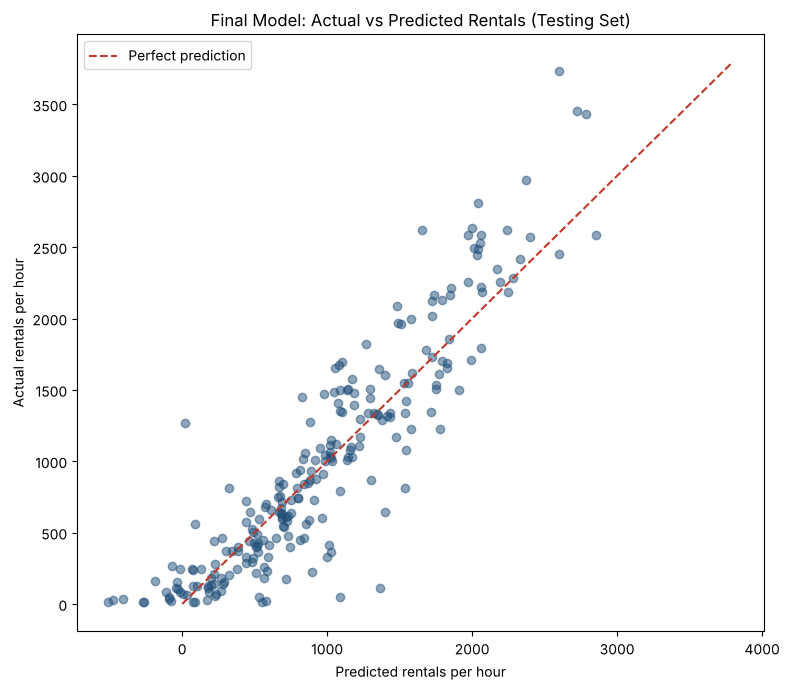

Average absolute error        : 239 rentals per hour
Median absolute error         : 157 rentals per hour
Average actual rentals (test) : 1,001 per hour
Busy hours (> 1,500)          : model predicts 275 too few on average
Negative predictions          : 16 of 238 testing hours
Test R2 with forecasts floored at zero (operational rule, not the model score): 0.8348


In [28]:
# predictions of the final model on the hours it has never seen (testing set)
x_train, x_test, y_train, y_test = train_test_split(x_final, y_rentals,
                                                    test_size = 0.35, random_state = 702)
final_pred = final_model.predict(x_test)


# actual vs predicted rentals
fig, ax = plt.subplots(figsize = (8, 7))

ax.scatter(final_pred, y_test, alpha = 0.5, color = '#1f4e79')
ax.plot([0, 3800], [0, 3800], color = '#c0392b', linestyle = '--', label = 'Perfect prediction')
ax.set_title('Final Model: Actual vs Predicted Rentals (Testing Set)')
ax.set_xlabel('Predicted rentals per hour')
ax.set_ylabel('Actual rentals per hour')
ax.legend()


# rendering the plot
plt.tight_layout()
plt.show()


# typical size of an hourly prediction error on the testing set
print(f"Average absolute error        : {np.mean(np.abs(y_test - final_pred)):,.0f} rentals per hour")
print(f"Median absolute error         : {np.median(np.abs(y_test - final_pred)):,.0f} rentals per hour")
print(f"Average actual rentals (test) : {y_test.mean():,.0f} per hour")

# busiest hours: average error when actual demand is above 1,500 (positive = model predicts too few)
busy = y_test > 1500
print(f"Busy hours (> 1,500)          : model predicts {np.mean(y_test[busy] - final_pred[busy]):,.0f} too few on average")
print(f"Negative predictions          : {(final_pred < 0).sum()} of {len(final_pred)} testing hours")


# separate, clearly labelled check: R-square if negative forecasts are set to zero (NOT the official score)
clipped = np.clip(final_pred, 0, None)
r2_clip = r2_score(y_test, clipped)  # metric calculation, not a transformed predictor
print(f"Test R2 with forecasts floored at zero (operational rule, not the model score): {r2_clip:.4f}")

**How accurate the predictions are**

* Each dot is one of the 238 test hours, and the closer a dot is to the red line, the better the prediction.
* The dots follow the line from quiet nights to busy evenings.
* The average error is 239 rentals per hour (median 157), while the average demand is about 1,000 rentals per hour.
* In the busiest hours (above 1,500 rentals) the model predicts about 275 rentals too few, so peak supply should be checked.
* Sixteen test hours get negative predictions, and setting them to 0 gives an R-square of 0.835, but the official model score stays 0.827.

In [29]:
# translating the coefficients into business scenarios (change in rentals per hour)
coef     = pd.Series(final_model.coef_, index = x_final.columns)


# each scenario combines the coefficients that switch on together
effects = pd.Series({
    'Working day vs off-day, 8 am'          : coef['rush'] + coef['am_peak'] - coef['offday'],
    'Working day vs off-day, 5-7 pm'        : coef['rush'] + coef['pm_peak'] - coef['offday'],
    'Rain in the hour'                      : coef['rain'],
    'Very humid hour (80% or more)'         : coef['humid_high'],
    'Pleasant evening (15 C+, 4-11 pm)'     : coef['pleasant_evening'],
    '5 degrees C warmer'                    : coef['Temperature'] * 5,
    'June vs March'                         : coef['month_June'] - coef['month_Mar']
})

effects.round(0).to_frame('Change in rentals per hour')

,Change in rentals per hour
"Working day vs off-day, 8 am",914.0
"Working day vs off-day, 5-7 pm",-37.0
Rain in the hour,-451.0
Very humid hour (80% or more),-260.0
"Pleasant evening (15 C+, 4-11 pm)",602.0
5 degrees C warmer,80.0
June vs March,392.0


In [30]:
def prepare_prediction_inputs(records):
    """Builds the final model's x-features from raw records (same columns as the Excel file)."""
    frame = records[weather + ['Month', 'Hour', 'Holiday', 'Day of Week']].copy()

    # input checks: no missing values, numbers where numbers are expected, known categories only
    if frame.isna().any().any():
        raise ValueError('Prediction inputs cannot contain missing values.')
    if not all(pd.api.types.is_numeric_dtype(frame[col]) for col in weather + ['Hour']):
        raise ValueError('Weather columns and Hour must be numeric.')
    if not frame['Hour'].between(0, 23).all():
        raise ValueError('Hour must be between 0 and 23.')
    if not frame['Month'].isin(['Mar', 'Apr', 'May', 'June']).all():
        raise ValueError('The model only covers March to June.')
    if not frame['Holiday'].isin(['Yes', 'No']).all():
        raise ValueError('Holiday must be Yes or No.')
    if not frame['Day of Week'].isin(raw_bikes['Day of Week'].unique()).all():
        raise ValueError('Unknown day of the week.')

    # calendar flags, defined exactly as in Part III
    frame['holiday'] = frame.Holiday.eq('Yes').astype(int)
    frame['offday'] = (frame['Day of Week'].isin(['Saturday', 'Sunday']) | frame.Holiday.eq('Yes')).astype(int)
    frame['rush'] = (frame.offday.eq(0) & frame.Hour.isin([7, 8, 9, 17, 18, 19])).astype(int)
    frame['am_peak'] = (frame.offday.eq(0) & frame.Hour.eq(8)).astype(int)
    frame['pm_peak'] = (frame.offday.eq(0) & frame.Hour.isin([17, 18, 19])).astype(int)

    # weather flags, defined exactly as in Part III
    frame['rain'] = frame.Rainfall.gt(0).astype(int)
    frame['humid_high'] = frame.Humidity.ge(80).astype(int)
    frame['pleasant_evening'] = (frame.Temperature.ge(15) & frame.Hour.between(16, 22)).astype(int)

    # hour and month dummies, then the exact column order of the final model
    encoded = pd.concat([frame[weather + ['holiday', 'offday', 'rush', 'am_peak', 'pm_peak',
                                        'rain', 'humid_high', 'pleasant_evening']],
                         pd.get_dummies(frame.Hour, prefix='hour', dtype=int),
                         pd.get_dummies(frame.Month, prefix='month', dtype=int)], axis=1)
    return encoded.reindex(columns=x_final.columns, fill_value=0).astype(float)


# check: rebuilding all 678 rows gives exactly the training features
assert np.array_equal(prepare_prediction_inputs(raw_bikes).to_numpy(), x_final.to_numpy())


# check: an hour outside the training months (July) is rejected instead of silently accepted
try:
    prepare_prediction_inputs(raw_bikes.head(1).assign(Month = 'July'))
except ValueError as error:
    print('Rejected input as expected:', error)


# example: a dry 14-degree working-day 8 am hour in May
example_raw = pd.DataFrame([{'Month': 'May', 'Hour': 8, 'Holiday': 'No',
    'Day of Week': 'Monday', 'Temperature': 14, 'Humidity': 55, 'Wind Speed': 1.5,
    'Visibility': 1800, 'UV Index': .5, 'Rainfall': 0}])
example = prepare_prediction_inputs(example_raw)
print(f'Predicted rentals for this hour: {final_model.predict(example)[0]:,.0f}')

Rejected input as expected: The model only covers March to June.
Predicted rentals for this hour: 1,639


In [31]:
# documenting the final model: model type and feature groups
print(f"Final model : {type(final_model).__name__}() from scikit-learn, {x_final.shape[1]} x-features")
print("Weather     :", ', '.join(w for w in weather if w != 'Rainfall'), "(Rainfall used as a yes/no rain flag)")
print("Calendar    : 23 hour dummies (base = midnight), 3 month dummies (base = April), holiday, offday")
print("Flags       : rush, am_peak, pm_peak, rain, humid_high, pleasant_evening")

Final model : LinearRegression() from scikit-learn, 39 x-features
Weather     : Temperature, Humidity, Wind Speed, Visibility, UV Index (Rainfall used as a yes/no rain flag)
Calendar    : 23 hour dummies (base = midnight), 3 month dummies (base = April), holiday, offday
Flags       : rush, am_peak, pm_peak, rain, humid_high, pleasant_evening


<h3>Final model: linear regression (test R-square 0.827, gap 0.037)</h3>

We recommend the linear model with weather, hour, month, commute flags, rain (yes/no) and the pleasant-evening flag. Its test R-square of 0.827 ties with the best stable model, and it has a gap of 0.037 and the best training CV score (0.725). It beats the best stable tree by 0.12. Holding the other inputs constant, an 8 am hour on a working day is associated with about 910 more rentals than the same hour on a weekend or holiday. Holding the other inputs constant, the pleasant-evening flag is associated with about 600 more rentals per hour. The rain flag is associated with about 450 fewer rentals per hour, and the high-humidity flag adds a further adjustment of about -260, which is not the full difference between a dry and a humid hour. For example, a dry working-day 8 am hour in May at 14 degrees is predicted at about 1,640 rentals. For the next hour the model can use current weather, but for the next day it needs a weather forecast, which adds some extra error. The model learned only from March to June, so it should be monitored and retrained with data from the rest of the year.

<hr style="height:.9px;border:none;color:#333;background-color:#333;" />
<h2>Part VIII: Recommendations for Cook County</h2>

**What the County can do now**

* The County should plan bike availability for the working-day peaks from 7 to 9 am and from 5 to 7 pm.
* The County should use the full demand forecast, which includes temperature, humidity and rain, to guide how many bikes to keep in service each day.
* The County should do routine maintenance from 2 to 6 am on cool nights and use cool rainy hours for bigger jobs.
* The County can use the final model hour by hour for March to June, set negative predictions to 0, and track its errors.

**What needs more data**

* Station-level demand, fleet size, staff and costs are needed before the County sets exact station targets or crew sizes.
* The holiday coding, the UV Index column, the 0% humidity reading and the Rainfall value of 35 should be checked at the source.
* Data from July to February is needed so that the model and maintenance windows cover the whole year.
* A rider survey on trip purpose would measure commuting directly instead of inferring it from the time of day.

<hr style="height:.9px;border:none;color:#333;background-color:#333;" />
<h2>Modeling Rules Checklist</h2>

| Rule | How this notebook meets it |
|---|---|
| Model types | Only `LinearRegression()` and `DecisionTreeRegressor()` from scikit-learn (`StandardScaler` only rescales inputs for Task 2) |
| No polynomial or rooted x-variables | Only original columns, dummy variables and yes/no flags; no squares, roots, logs or exponents |
| y-variable not on the x-side | `RENTALS` is used only as y; no feature is built from it, and `ID` is excluded |
| Processing time | Well under 60 seconds (timed in the final check cell) |
| Error-free and commented | Runs top to bottom without errors, with comments throughout the code |
| Train-test gap ≤ 0.05 | Final model gap = 0.037 (training 0.790, test 0.827) |
| Selection rule | Gap ≤ 0.05, then highest test R-square; scores within 0.001 count as a tie, broken by training CV |
| Honest model selection | Training CV is shown for every model; the test split was also viewed during exploration, so it is not a fully independent check |

<hr style="height:.9px;border:none;color:#333;background-color:#333;" />
<h2>References</h2>
Bean, R., Pojani, D., & Corcoran, J. (2021). How does weather affect bikeshare use? A comparative analysis of forty cities across climate zones. *Journal of Transport Geography, 95*, Article 103155. https://doi.org/10.1016/j.jtrangeo.2021.103155

Lu, J., Li, Z., & Guo, Q. (2026). Exploring the determinants of bike-sharing member trips with explainable machine learning: Insights from Chicago's Divvy system. *Computational Urban Science, 6*(1), Article 22. https://doi.org/10.1007/s43762-026-00254-9

Miranda-Moreno, L. F., & Nosal, T. (2011). Weather or not to cycle: Temporal trends and impact of weather on cycling in an urban environment. *Transportation Research Record, 2247*(1), 42-52. https://doi.org/10.3141/2247-06

## Final Execution Checks
The cell below checks the final model against the assignment rules automatically.

In [32]:
# Verify the fitted estimator, feature replay, coverage, and runtime before submission.
# allowed model type, no target/ID/Snowfall on the x-side, gap rule, 10% coverage
assert isinstance(final_model, LinearRegression)
assert not {'RENTALS', 'ID', 'Snowfall'}.intersection(x_final.columns)
assert summary_final['Abs. Gap'] <= .05
assert union.sum() >= int(np.ceil(.10 * len(bikes)))
assert np.array_equal(prepare_prediction_inputs(raw_bikes).to_numpy(), x_final.to_numpy())

# runtime since the imports cell
elapsed_seconds = perf_counter() - started

print(f"Raw-model test R2: {summary_final['Testing R2']:.6f}")
print(f"Absolute gap: {summary_final['Abs. Gap']:.6f}")
print(f"Maintenance coverage: {union.sum()} / {len(bikes)} ({union.mean():.1%})")
print(f"Execution time after imports: {elapsed_seconds:.2f} seconds")
assert elapsed_seconds < 60, 'Runtime exceeds the assignment limit on this computer.'

Raw-model test R2: 0.827264
Absolute gap: 0.036928
Maintenance coverage: 122 / 678 (18.0%)
Execution time after imports: 3.53 seconds


<h2>AI Usage Acknowledgment</h2>

* Claude (Anthropic) helped to explore the data, write code and text, and find external sources.
* ChatGPT / Codex (OpenAI) reviewed the notebook and suggested changes to the code and wording.
* Seyha Seng reviewed all code, numbers and sources before submission.
* The conversation links are: [add links].